---
title: "3.1.b Amenaza por inundación fluvial"
short_title: "b. Amenaza"
subtitle: "Crecientes del Amazonas en la regla de Leticia, periodos de retorno y mapas de inundación"
description: "Análisis de la amenaza por creciente del río Amazonas en Leticia con la serie diaria del IDEAM (1987–2026), GloFAS y los mapas globales del JRC."
keywords: [inundación, Amazonas, IDEAM, GEV, periodo de retorno, GloFAS, JRC]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/31_inundacion/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La creciente del Amazonas es lenta y predecible: el río sube durante meses y alcanza su máximo entre marzo y
junio. Esa regularidad es el **pulso de inundación** que sostiene la várzea [@junk1989]. La amenaza aparece
cuando el pulso es más alto o más largo de lo habitual. Este cuaderno la caracteriza con tres fuentes
complementarias:

1. la **serie diaria de nivel** de la estación LETICIA [48017010] del IDEAM, desde 1987;
2. el **caudal simulado** de GloFAS v4 en el cauce principal, desde 1984 [@grimaldi2022glofas];
3. los **mapas globales de amenaza** del JRC, con profundidades para periodos de retorno de 10 a 500 años
   [@baugh2024jrc].

## 1. Serie de nivel y control de calidad

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, hidro, viz
from leticia.config import parametros

tabla_ideam = fuentes.nivel_rio("NV_MEDIA_D", con_aprobacion=True)
crudo = tabla_ideam["nivel_cm"]
nivel = hidro.limpiar_nivel(crudo)
aprob = tabla_ideam["aprobacion"]
display(pd.Series({
    "Periodo": f"{nivel.first_valid_index():%Y-%m-%d} a {nivel.last_valid_index():%Y-%m-%d}",
    "Días con dato": int(nivel.notna().sum()),
    "Registros descartados por control de calidad (incluye 2007)": int(crudo.notna().sum() - nivel.notna().sum()),
    "Datos definitivos (%)": round(100 * (aprob == "Definitivo").mean(), 1),
    "Nivel máximo registrado (cm)": f"{nivel.max():.0f} ({nivel.idxmax():%Y-%m-%d})",
    "Nivel mínimo registrado (cm)": f"{nivel.min():.0f} ({nivel.idxmin():%Y-%m-%d})",
}, name="valor").to_frame())

,valor
Periodo,1987-12-01 a 2026-10-11
Días con dato,11014
Registros descartados por control de calidad (incluye 2007),404
Datos definitivos (%),92.90
Nivel máximo registrado (cm),1852 (2015-05-18)
Nivel mínimo registrado (cm),224 (2024-09-26)


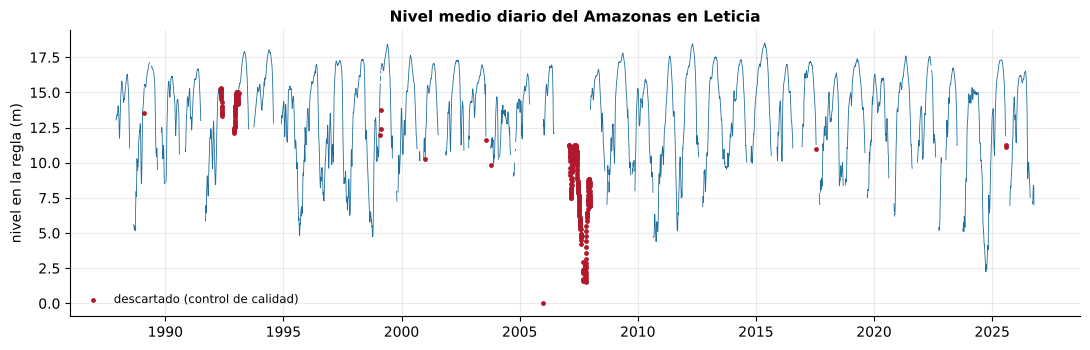

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(nivel.index, nivel / 100, color=viz.AZUL_RIO, lw=0.6)
descartados = crudo[nivel.reindex(crudo.index).isna() & crudo.notna()]
ax.scatter(descartados.index, descartados / 100, s=6, color=viz.ROJO, label="descartado (control de calidad)", zorder=3)
ax.set_ylabel("nivel en la regla (m)")
ax.set_title("Nivel medio diario del Amazonas en Leticia")
ax.legend(loc="lower left")
fig.tight_layout()

In [4]:
viz.pie(viz.nota_fuente("nivel_rio_leticia"))

*Fuente: IDEAM — Estación limnimétrica LETICIA [48017010], series NV_MEDIA_D, NV_MN_D y NV_MX_D.*

El control de calidad elimina valores imposibles (ceros y registros bajo 1 m) y saltos de más de 1,2 m frente a
la mediana móvil de 15 días: un río de este tamaño no cambia tanto de un día a otro. Además **se excluye 2007**:
de febrero a diciembre de ese año la serie publicada queda entre 5 y 7 m por debajo de su climatología todos los
meses (su máximo de aguas altas sería 11 m, cuando ningún otro año baja de 14 m), señal de un cambio del cero de
la regla que no fue corregido. Sin esa exclusión, 2007 aparecería falsamente como la peor sequía del registro. Las lagunas de la serie
(años con meses sin dato) obligan a exigir un mínimo de días en cada temporada para usar el máximo o el
mínimo de ese año.

## 2. El ciclo anual: aguas altas y aguas bajas

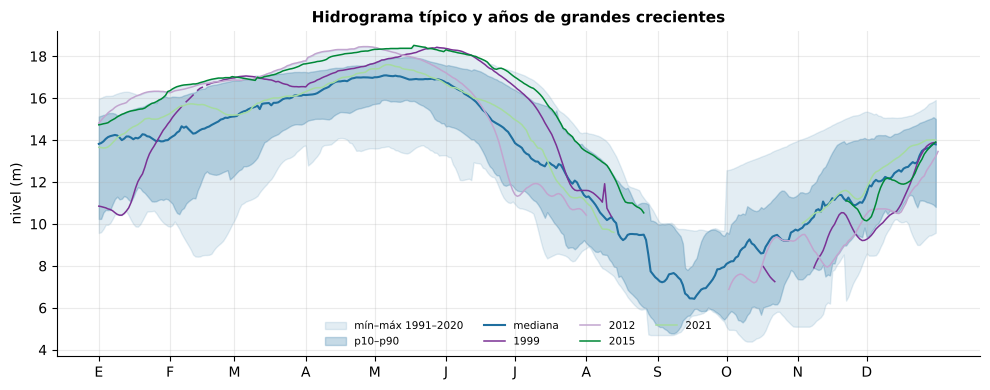

In [5]:
clim = hidro.climatologia_diaria(nivel, base=(1991, 2020))
fig, ax = plt.subplots(figsize=(10, 4))
x = clim.index
ax.fill_between(x, clim["min"] / 100, clim["max"] / 100, color=viz.AZUL_RIO, alpha=0.12, label="mín–máx 1991–2020")
ax.fill_between(x, clim["p10"] / 100, clim["p90"] / 100, color=viz.AZUL_RIO, alpha=0.25, label="p10–p90")
ax.plot(x, clim["p50"] / 100, color=viz.AZUL_RIO, lw=1.5, label="mediana")
for anio, color in ((1999, "#7b3294"), (2012, "#c2a5cf"), (2015, "#008837"), (2021, "#a6dba0")):
    s = nivel[nivel.index.year == anio]
    ax.plot(s.index.dayofyear, s / 100, color=color, lw=1.1, label=str(anio))
ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_ylabel("nivel (m)")
ax.set_title("Hidrograma típico y años de grandes crecientes")
ax.legend(ncol=4, fontsize=7.5, loc="lower center")
fig.tight_layout()

In [6]:
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
mes = lambda doy: MESES[(pd.Timestamp("2001-01-01") + pd.Timedelta(days=int(doy) - 1)).month - 1]
suave = clim["p50"].rolling(15, center=True, min_periods=1).mean()
amplitud = (suave.max() - suave.min()) / 100
display(Markdown(f"La mediana sube de **{suave.min()/100:.1f} m** en aguas bajas a **{suave.max()/100:.1f} m** "
                 f"en aguas altas: una oscilación típica de **{amplitud:.1f} m** al año. El máximo suele llegar en "
                 f"**{mes(suave.idxmax())}** y el mínimo en **{mes(suave.idxmin())}**."))

La mediana sube de **6.8 m** en aguas bajas a **17.0 m** en aguas altas: una oscilación típica de **10.2 m** al año. El máximo suele llegar en **mayo** y el mínimo en **septiembre**.

## 3. Máximos anuales y tendencia

Años con dato suficiente: **38**. Tendencia de Mann-Kendall: z = 0.31, p = 0.75; pendiente de Sen **0.3 cm/año**. Los cinco máximos más altos: 2015 (18.52 m), 2012 (18.46 m), 1999 (18.43 m), 1994 (18.04 m), 1993 (17.92 m).

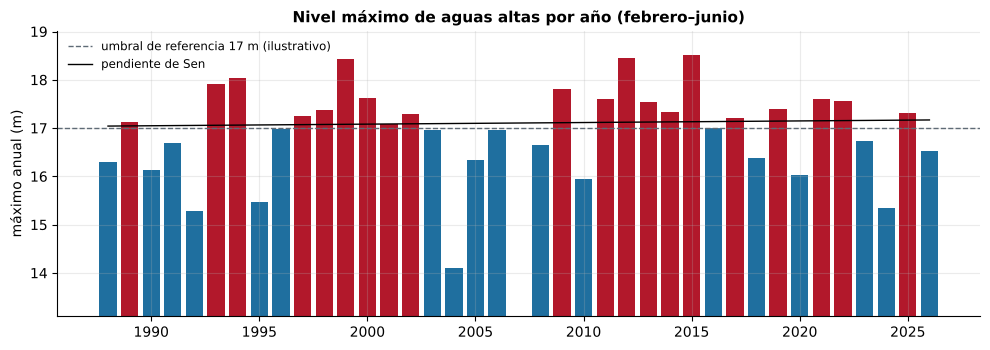

In [7]:
maximos = hidro.extremos_anuales(nivel, "max")
mk = hidro.mann_kendall(maximos["valor"])
umbral = parametros()["hidrologia"]["umbral_creciente_cm"]
fig, ax = plt.subplots(figsize=(10, 3.6))
colores = np.where(maximos["valor"] >= umbral, viz.ROJO, viz.AZUL_RIO)
ax.bar(maximos.index, maximos["valor"] / 100, color=colores)
ax.axhline(umbral / 100, color=viz.GRIS, ls="--", lw=1, label=f"umbral de referencia {umbral/100:.0f} m (ilustrativo)")
t = np.array(maximos.index, dtype=float)
ax.plot(t, (np.median(maximos["valor"]) + mk["sen"] * (t - np.median(t))) / 100, color="k", lw=1, label="pendiente de Sen")
ax.set_ylim(maximos["valor"].min() / 100 - 1, maximos["valor"].max() / 100 + 0.5)
ax.set_ylabel("máximo anual (m)")
ax.set_title("Nivel máximo de aguas altas por año (febrero–junio)")
ax.legend(loc="upper left")
fig.tight_layout()
display(Markdown(f"Años con dato suficiente: **{mk['n']}**. Tendencia de Mann-Kendall: z = {mk['z']:.2f}, p = {mk['p']:.2f}; "
                 f"pendiente de Sen **{mk['sen']:.1f} cm/año**. Los cinco máximos más altos: "
                 + ", ".join(f"{a} ({v/100:.2f} m)" for a, v in maximos['valor'].nlargest(5).items()) + "."))

**Lectura.** Las mayores crecientes de la serie se concentran en 1999, 2012 y 2015, en línea con la
intensificación de las crecientes amazónicas documentada desde finales de los años noventa: en la primera
mitad del siglo XX una gran creciente ocurría cada ~20 años y desde 2000 ocurre una cada ~4 años
[@marengo2021spa22; @barichivich2018]. Con unas tres décadas de datos y lagunas, la tendencia local no es
estadísticamente concluyente; la señal regional, basada en el registro centenario de Manaos, sí lo es.

## 4. Periodos de retorno de la creciente

,nivel (m),IC 5 %,IC 95 %
periodo_retorno,,,
2,17.09,16.78,17.30
5,17.78,17.50,17.99
10,18.05,17.76,18.30
25,18.27,17.90,18.59
50,18.37,17.95,18.78
100,18.43,17.97,18.91


Parámetro de forma de la GEV (convención de SciPy): c = 0.56. Con c > 0 la distribución tiene **cota superior** (≈ 18.57 m): por encima de cierto nivel el agua se expande sobre la várzea y el nivel sube cada vez menos.

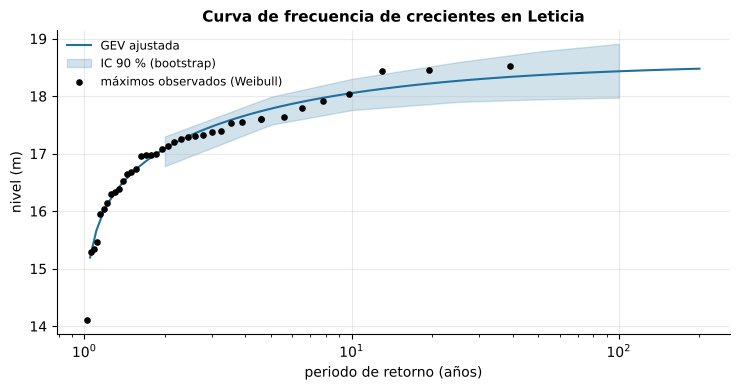

In [8]:
T = parametros()["periodos_retorno"]
ret = hidro.niveles_retorno_ic(maximos["valor"].values, T)
emp = hidro.periodo_retorno_empirico(maximos["valor"])
fig, ax = plt.subplots(figsize=(7.5, 4))
tt = np.logspace(np.log10(1.05), np.log10(200), 100)
params = hidro.ajustar_gev(maximos["valor"].values)
ax.plot(tt, hidro.nivel_retorno(params, tt) / 100, color=viz.AZUL_RIO, label="GEV ajustada")
ax.fill_between(ret.index, ret["ic5"] / 100, ret["ic95"] / 100, color=viz.AZUL_RIO, alpha=0.2, label="IC 90 % (bootstrap)")
ax.scatter(emp, maximos["valor"] / 100, color="k", s=14, zorder=3, label="máximos observados (Weibull)")
ax.set_xscale("log")
ax.set_xlabel("periodo de retorno (años)")
ax.set_ylabel("nivel (m)")
ax.set_title("Curva de frecuencia de crecientes en Leticia")
ax.legend()
fig.tight_layout()
display((ret / 100).round(2).rename(columns={"nivel": "nivel (m)", "ic5": "IC 5 %", "ic95": "IC 95 %"}))
cota = params[1] + params[2] / params[0] if params[0] > 0 else np.inf
display(Markdown(f"Parámetro de forma de la GEV (convención de SciPy): c = {params[0]:.2f}. "
                 + (f"Con c > 0 la distribución tiene **cota superior** (≈ {cota/100:.2f} m): por encima de cierto nivel el agua se "
                    "expande sobre la várzea y el nivel sube cada vez menos." if params[0] > 0 else "La cola superior no está acotada.")))

La distribución generalizada de valores extremos (GEV) se ajusta por máxima verosimilitud a los máximos
anuales [@coles2001extremes]. Con ~35 años de datos, los niveles de 50 y 100 años son **extrapolaciones** con
intervalos amplios; sirven para comparar escenarios, no para diseñar obras sin un estudio hidráulico.

## 5. Caudal simulado por GloFAS y relación con el nivel

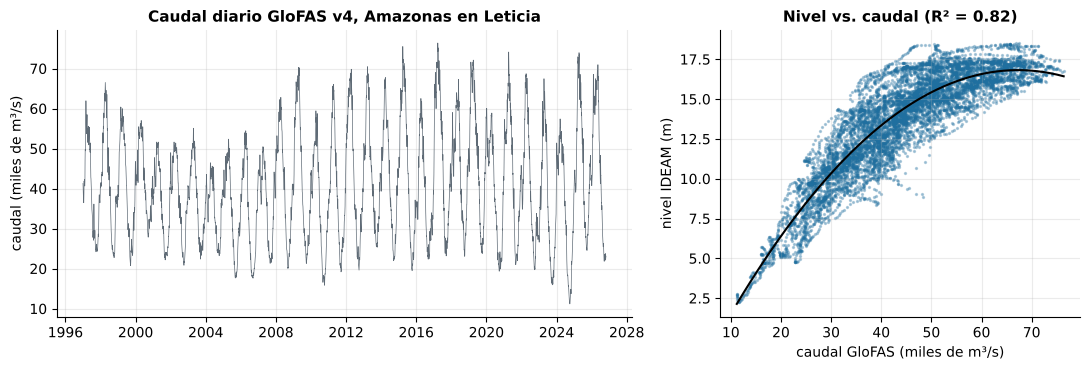

In [9]:
q = fuentes.caudal_glofas()
coef, r2, comun = hidro.relacion_nivel_caudal(nivel, q)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(q.index, q / 1000, color=viz.GRIS, lw=0.5)
ax[0].set_ylabel("caudal (miles de m³/s)")
ax[0].set_title("Caudal diario GloFAS v4, Amazonas en Leticia")
ax[1].scatter(comun["caudal"] / 1000, comun["nivel"] / 100, s=2, alpha=0.3, color=viz.AZUL_RIO)
xx = np.linspace(comun["caudal"].min(), comun["caudal"].max(), 50)
ax[1].plot(xx / 1000, np.polyval(coef, xx) / 100, color="k")
ax[1].set_xlabel("caudal GloFAS (miles de m³/s)")
ax[1].set_ylabel("nivel IDEAM (m)")
ax[1].set_title(f"Nivel vs. caudal (R² = {r2:.2f})")
fig.tight_layout()

In [10]:
viz.pie(viz.nota_fuente("caudal_glofas", "nivel_rio_leticia"))

*Fuente: Copernicus EMS – GloFAS v4 (vía Open-Meteo) — river_discharge diario 1984–presente, celda 0,05°; IDEAM — Estación limnimétrica LETICIA [48017010], series NV_MEDIA_D, NV_MN_D y NV_MX_D.*

**Lectura.** GloFAS reproduce bien el ciclo anual y su relación con la regla de Leticia permite **convertir los
pronósticos de caudal en niveles esperados**. Es la base de la alerta temprana de la sección d. El caudal
medio del Amazonas frente a Leticia ronda los 40 000 m³/s, con crecientes de más de 70 000 m³/s.

## 6. Mapas de amenaza: profundidad por periodo de retorno

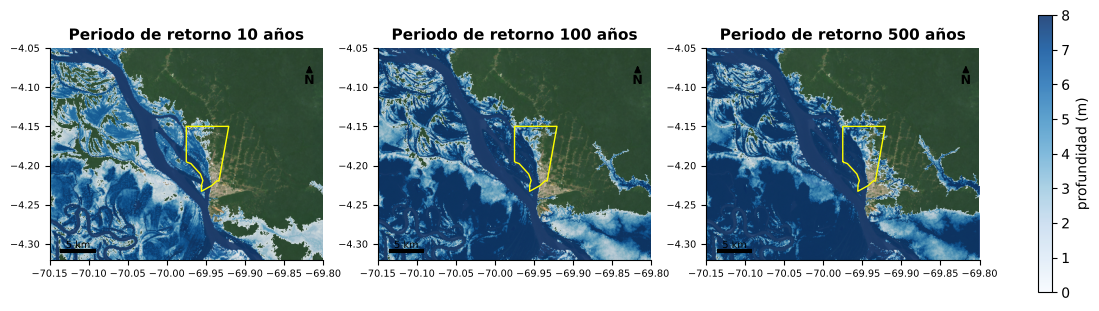

In [11]:
from leticia import aoi
urbana = aoi.area_urbana().to_crs(4326)
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, rp in zip(ax, (10, 100, 500)):
    d = fuentes.inundacion_jrc(rp)
    viz.fondo(a, "bbox_regional")
    im = a.imshow(np.where(d.values > 0, d.values, np.nan), extent=(float(d.x.min()), float(d.x.max()), float(d.y.min()), float(d.y.max())),
                  cmap="Blues", vmin=0, vmax=8, alpha=0.85, zorder=2)
    urbana.boundary.plot(ax=a, color="yellow", lw=1, zorder=3)
    viz.marco(a, "bbox_regional", f"Periodo de retorno {rp} años")
fig.colorbar(im, ax=ax, shrink=0.6, label="profundidad (m)")

In [12]:
viz.pie(viz.nota_fuente("inundacion_jrc"))

*Fuente: JRC – Copernicus EMS (GloFAS) — Global river flood hazard maps v2.1 (RP10–RP500), LISFLOOD-FP.*

Los mapas del JRC resultan de simular con LISFLOOD-FP, a ~90 m, los caudales de GloFAS para cada periodo de
retorno. Muestran la llanura de inundación de la margen peruana y las islas, que se inundan con frecuencia, y
las **zonas bajas de la ciudad junto al río y a las quebradas**. A esta resolución no distinguen calles ni
rellenos: el análisis de riesgo (c) los complementa con la altura de cada lugar sobre el río.

## 7. Lo que muestran 37 años de satélite: frecuencia de agua

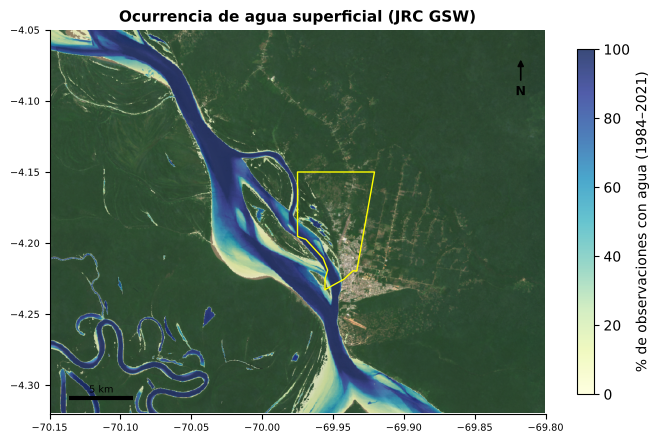

In [13]:
occ = fuentes.raster_estatico("jrc-gsw", "occurrence")
fig, ax = plt.subplots(figsize=(8, 6.4))
viz.fondo(ax, "bbox_regional")
v = occ.where(occ > 0)
im = ax.imshow(v.values, extent=(float(occ.x.min()), float(occ.x.max()), float(occ.y.min()), float(occ.y.max())), cmap="YlGnBu",
               vmin=0, vmax=100, alpha=0.8, zorder=2)
urbana.boundary.plot(ax=ax, color="yellow", lw=1, zorder=3)
fig.colorbar(im, ax=ax, shrink=0.7, label="% de observaciones con agua (1984–2021)")
viz.marco(ax, "bbox_regional", "Ocurrencia de agua superficial (JRC GSW)")

In [14]:
viz.pie(viz.nota_fuente("agua_superficial_jrc") + " Pekel et al. (2016).")

*Fuente: JRC – Global Surface Water (Pekel et al. 2016) — occurrence, seasonality, transitions, extent. Pekel et al. (2016).*

**Lectura.** Los valores intermedios (10–60 %) señalan áreas que el agua cubre solo en aguas altas: lagos de
Yahuarcaca, várzeas de las islas y orillas bajas. Son las primeras en inundarse. La ocurrencia también revela
la **migración del cauce**: franjas que pasaron de agua a tierra o al revés, que se estudian en
[3.3 Erosión y dinámica fluvial](../33_erosion/index.md).